# Лабораторная работа №5. Кластеризация данных

**Цель работы:** исследовать алгоритмы кластеризации различных семейств на синтетических и реальных данных, освоить методы подбора гиперпараметров кластеризации (метод локтя, силуэтный анализ, график $k$-расстояний, дендрограмма), оценить качество разбиения внутренними и внешними метриками, а также реализовать алгоритм `K-Means` с нуля.

### Исследуемые наборы данных
1. **`clf` (`make_classification`)** — 3 000 объектов, 2 информативных признака, 3 частично перекрывающихся кластера вытянутой формы;
2. **`blob` (`make_blobs`)** — 3 000 объектов, 2 признака, 4 компактных шарообразных кластера;
3. **`real` (`csv/cl_finished.csv`)** — стратифицированная подвыборка реального медицинского датасета `Diabetes_012` (21 признак).

### Алгоритмы кластеризации
* **K-Means** — центроидный метод минимизации внутрикластерной дисперсии (инерции);
* **DBSCAN** — плотностной метод, способный выделять кластеры произвольной формы и отсеивать выбросы (шум `-1`);
* **Gaussian Mixture (GMM)** — вероятностная EM-модель смеси гауссиан;
* **Agglomerative Clustering** — иерархическая агломеративная кластеризация (связь Уорда `ward`);
* **Affinity Propagation** — кластеризация на основе обмена сообщениями между парами точек (выбор «экземпляров-представителей»);
* **MyKMeans** — собственная векторная реализация алгоритма Ллойда (K-Means) на NumPy.

### Метрики качества
* **Внешние метрики** (сравнение с эталонными метками):
  * `ARI` (*Adjusted Rand Index*, от $-1$ до $1$);
  * `NMI` (*Normalized Mutual Information*, от $0$ до $1$).
* **Внутренние метрики** (оценка компактности и разделимости без истинных меток):
  * `Silhouette` (*коэффициент силуэта*, от $-1$ до $1$, больше — лучше);
  * `Davies-Bouldin` (*индекс Дэвиса–Болдина*, $\ge 0$, меньше — лучше).

## 1. Импорт библиотек и вспомогательные функции

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, davies_bouldin_score)
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, DBSCAN, AffinityPropagation, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [ ]:
def clustering_metrics(X, labels_true, labels_pred):
    metrics = {
        'ARI': adjusted_rand_score(labels_true, labels_pred),
        'NMI': normalized_mutual_info_score(labels_true, labels_pred),
    }
    unique_labels = set(labels_pred)
    if len(unique_labels) > 1:
        metrics['Silhouette'] = silhouette_score(X, labels_pred)
        metrics['Davies-Bouldin'] = davies_bouldin_score(X, labels_pred)
    else:
        metrics['Silhouette'] = np.nan
        metrics['Davies-Bouldin'] = np.nan
    return metrics


def build_table(results):
    rows = []
    for model_key, m_dict in results.items():
        dataset_name, alg_name = model_key.split('_', 1)
        row = {'Датасет': dataset_name, 'Алгоритм': alg_name, 'Модель': model_key}
        row.update(m_dict)
        rows.append(row)
    df = pd.DataFrame(rows).set_index('Модель')
    return df[['Датасет', 'Алгоритм', 'ARI', 'NMI', 'Silhouette', 'Davies-Bouldin']]


def plot_clusters_pair(dfs, models_dict, alg_name, show_centers=False):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, ds_name in zip(axes, ['clf', 'blob']):
        X_ds = dfs[ds_name][0]
        model, labels = models_dict[ds_name][alg_name]
        ax.scatter(X_ds[:, 0], X_ds[:, 1], c=labels, cmap='viridis', s=20, alpha=0.75)
        if show_centers:
            centers = getattr(model, 'cluster_centers_', getattr(model, 'means_', getattr(model, 'centroids', None)))
            if centers is not None:
                ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=180, edgecolors='black', label='Центры')
                ax.legend()
        ax.set_title(f'{ds_name.upper()} — {alg_name}')
        ax.set_xlabel('Признак 1')
        ax.set_ylabel('Признак 2')
    plt.tight_layout()
    plt.show()

## 2. Подготовка синтетических и реальных наборов данных

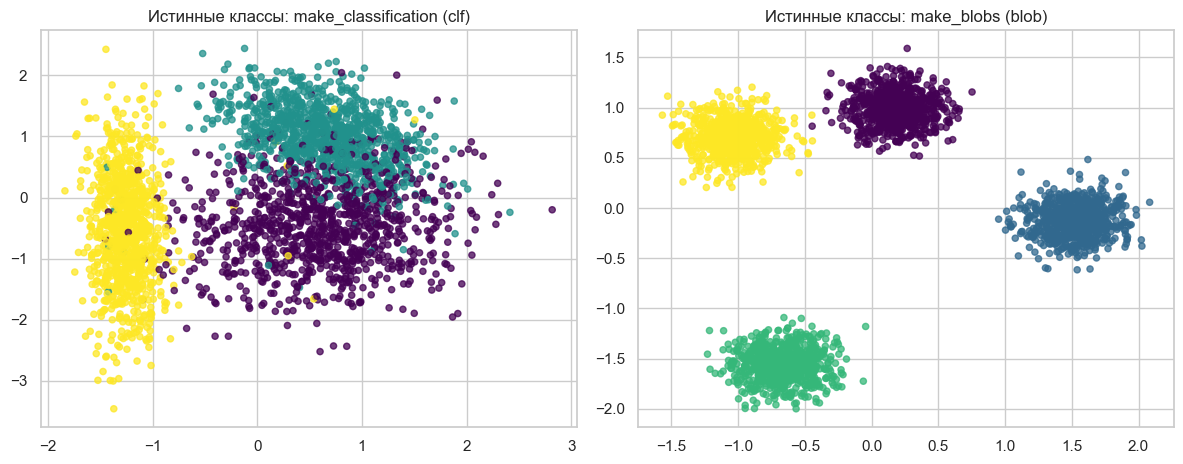

In [ ]:
df_real = pd.read_csv('csv/cl_finished.csv', sep=';')
X_real_full = df_real.drop(columns='Diabetes_012')
y_real_full = df_real['Diabetes_012']
X_real, _, y_real, _ = train_test_split(
    X_real_full, y_real_full, train_size=3000, random_state=RANDOM_STATE, stratify=y_real_full
)

X_mkcl, y_mkcl = make_classification(
    n_samples=3000, n_features=2, n_informative=2, n_redundant=0,
    n_classes=3, n_clusters_per_class=1, random_state=RANDOM_STATE
)

X_mkbl, y_mkbl = make_blobs(
    n_samples=3000, n_features=2, centers=4, random_state=RANDOM_STATE
)

X_mkcl = StandardScaler().fit_transform(X_mkcl)
X_mkbl = StandardScaler().fit_transform(X_mkbl)
X_real = StandardScaler().fit_transform(X_real)

dfs = {
    'clf': (X_mkcl, y_mkcl),
    'blob': (X_mkbl, y_mkbl),
    'real': (X_real, y_real.to_numpy()),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(X_mkcl[:, 0], X_mkcl[:, 1], c=y_mkcl, cmap='viridis', s=20, alpha=0.75)
axes[0].set_title('Истинные классы: make_classification (clf)')
axes[1].scatter(X_mkbl[:, 0], X_mkbl[:, 1], c=y_mkbl, cmap='viridis', s=20, alpha=0.75)
axes[1].set_title('Истинные классы: make_blobs (blob)')
plt.tight_layout()
plt.show()

## 3. Определение оптимального числа кластеров (Метод локтя и Силуэтный анализ)
Для каждого набора данных построим зависимость инерции (внутрикластерной суммы квадратов расстояний) и коэффициента силуэта от числа кластеров $k \in [2, 9]$.

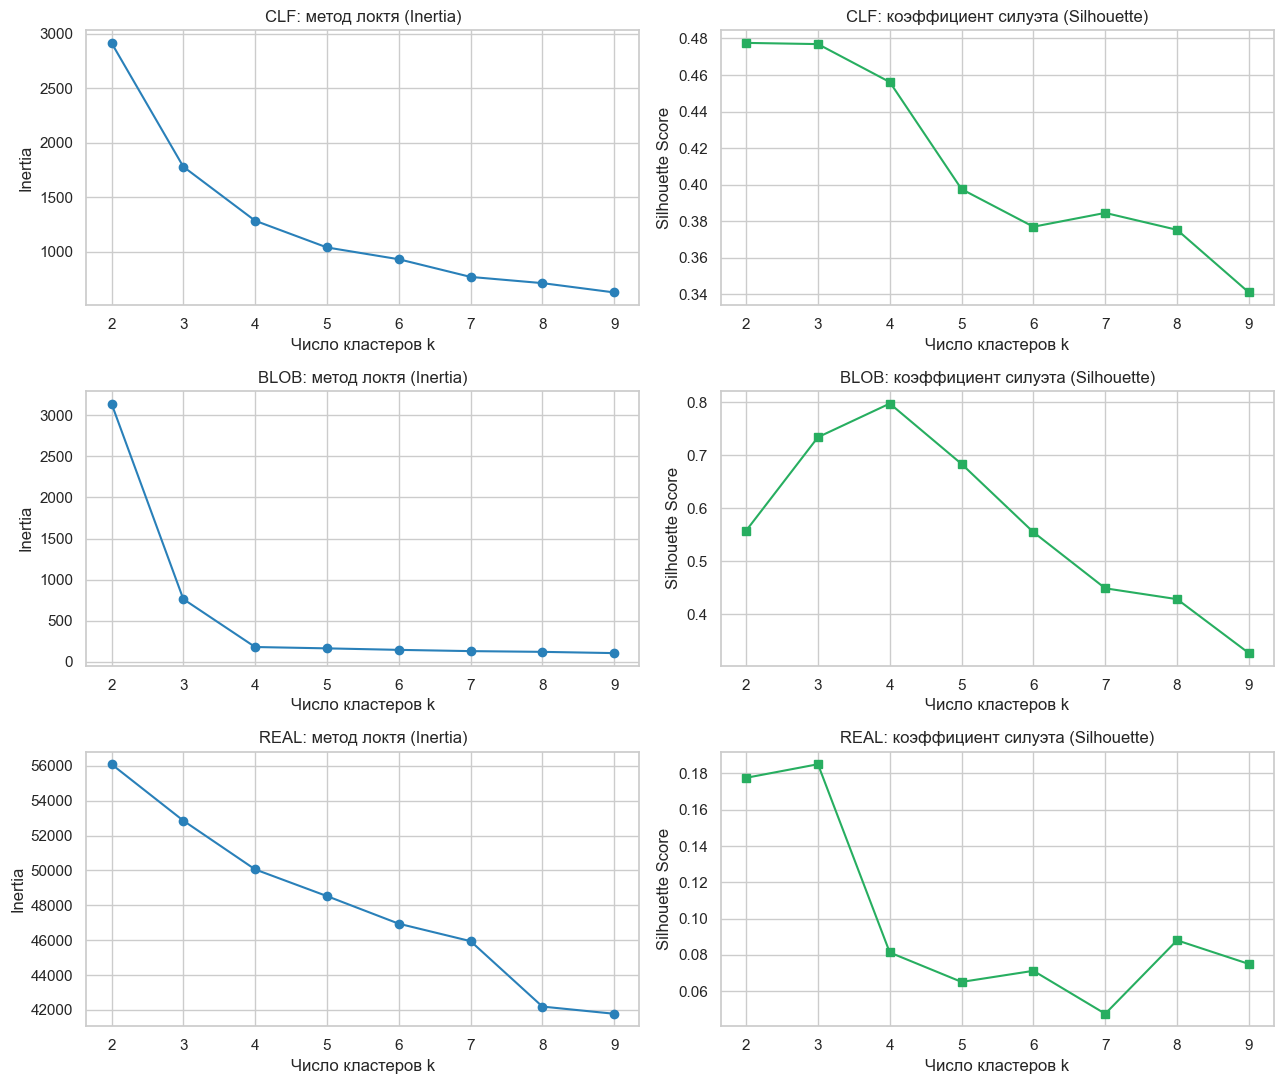

In [4]:
k_range = range(2, 10)
fig, axes = plt.subplots(3, 2, figsize=(13, 11))

for row_idx, ds_name in enumerate(['clf', 'blob', 'real']):
    X_ds = dfs[ds_name][0]
    inertias, silhouettes = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init='auto', random_state=RANDOM_STATE).fit(X_ds)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_ds, km.labels_))

    axes[row_idx, 0].plot(list(k_range), inertias, 'o-', color='#2980b9')
    axes[row_idx, 0].set_title(f'{ds_name.upper()}: метод локтя (Inertia)')
    axes[row_idx, 0].set_xlabel('Число кластеров k')
    axes[row_idx, 0].set_ylabel('Inertia')

    axes[row_idx, 1].plot(list(k_range), silhouettes, 's-', color='#27ae60')
    axes[row_idx, 1].set_title(f'{ds_name.upper()}: коэффициент силуэта (Silhouette)')
    axes[row_idx, 1].set_xlabel('Число кластеров k')
    axes[row_idx, 1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

По графикам локтя и максимуму коэффициента силуэта выбираем оптимальное число кластеров:
* **`clf`** — $k = 3$;
* **`blob`** — $k = 4$;
* **`real`** — $k = 2$ (максимум силуэта достигается при делении на 2 макрогруппы состояния здоровья).

## 4. Кластеризация методом K-Means

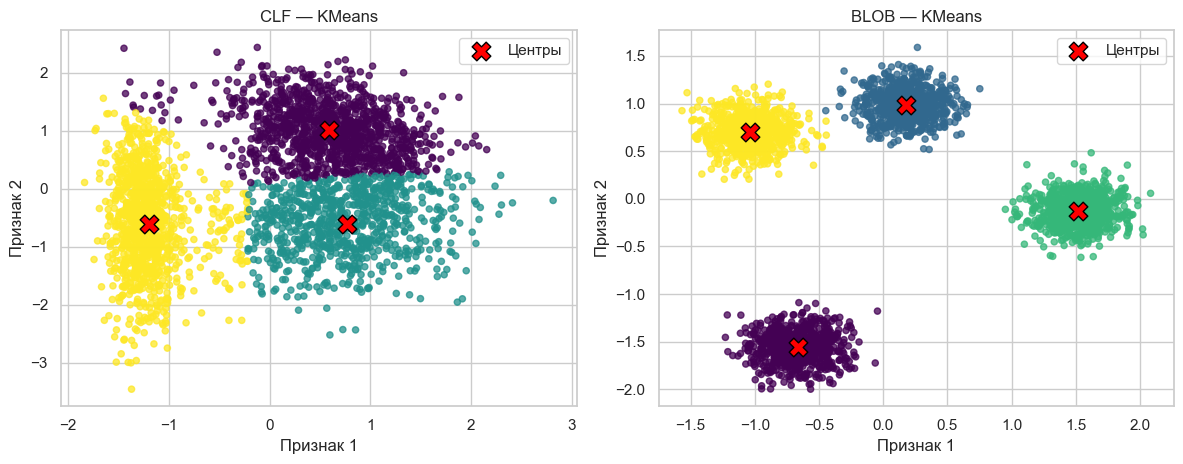

In [5]:
models = {'clf': {}, 'blob': {}, 'real': {}}
optimal_k = {'clf': 3, 'blob': 4, 'real': 2}

for ds_name, k in optimal_k.items():
    km = KMeans(n_clusters=k, n_init='auto', random_state=RANDOM_STATE)
    labels = km.fit_predict(dfs[ds_name][0])
    models[ds_name]['KMeans'] = (km, labels)

plot_clusters_pair(dfs, models, 'KMeans', show_centers=True)

## 5. Плотностная кластеризация DBSCAN и подбор радиуса $\varepsilon$
Для выбора радиуса окрестности `eps` отсортируем средние расстояния до $k=4$ ближайших соседей каждой точки и найдём точку резкого изгиба («колено» кривой).

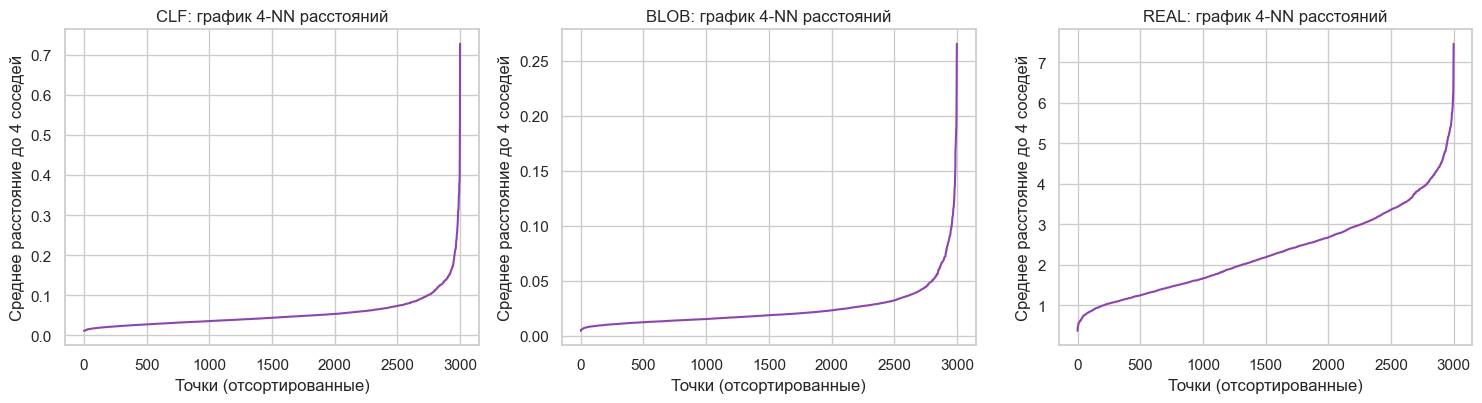

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, ds_name in zip(axes, ['clf', 'blob', 'real']):
    X_ds = dfs[ds_name][0]
    nbrs = NearestNeighbors(n_neighbors=5).fit(X_ds)
    distances, _ = nbrs.kneighbors(X_ds)
    k_dist = np.sort(distances[:, 1:].mean(axis=1))
    ax.plot(k_dist, color='#8e44ad')
    ax.set_title(f'{ds_name.upper()}: график 4-NN расстояний')
    ax.set_xlabel('Точки (отсортированные)')
    ax.set_ylabel('Среднее расстояние до 4 соседей')
plt.tight_layout()
plt.show()

Выбираем значения `eps`: для `clf` — `0.12`, для `blob` — `0.15`, для `real` — `2.2`.

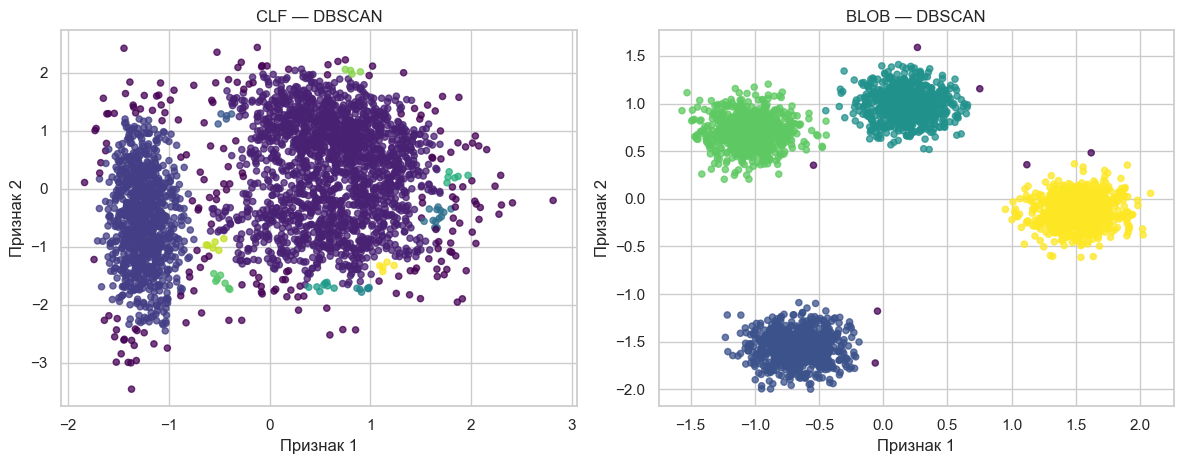

In [7]:
eps_map = {'clf': 0.12, 'blob': 0.15, 'real': 2.2}
for ds_name, eps_val in eps_map.items():
    db = DBSCAN(eps=eps_val, min_samples=5).fit(dfs[ds_name][0])
    models[ds_name]['DBSCAN'] = (db, db.labels_)

plot_clusters_pair(dfs, models, 'DBSCAN', show_centers=False)

## 6. Вероятностная кластеризация Gaussian Mixture (GMM)

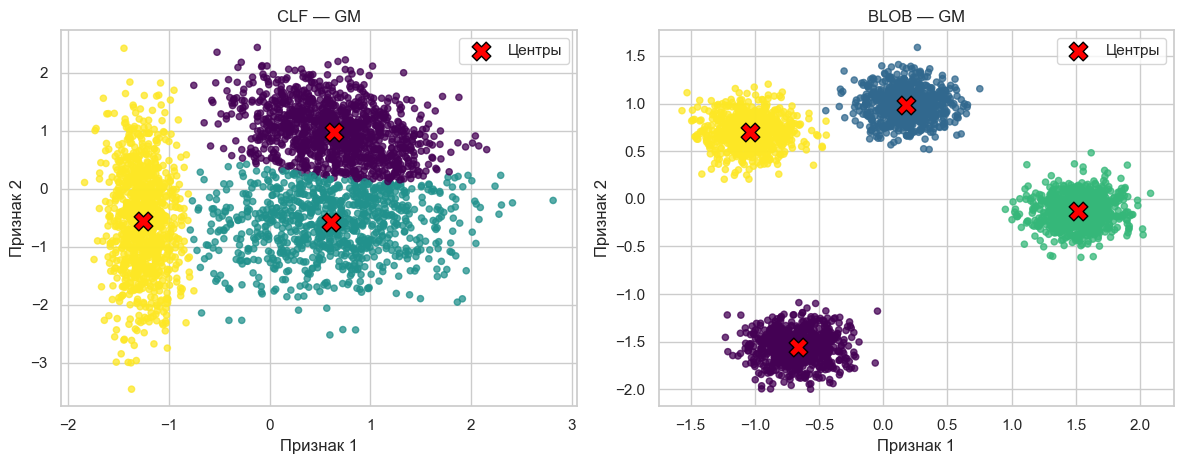

In [8]:
for ds_name, k in optimal_k.items():
    gm = GaussianMixture(n_components=k, random_state=RANDOM_STATE).fit(dfs[ds_name][0])
    labels = gm.predict(dfs[ds_name][0])
    models[ds_name]['GM'] = (gm, labels)

plot_clusters_pair(dfs, models, 'GM', show_centers=True)

## 7. Иерархическая кластеризация (Дендрограмма Уорда и AgglomerativeClustering)

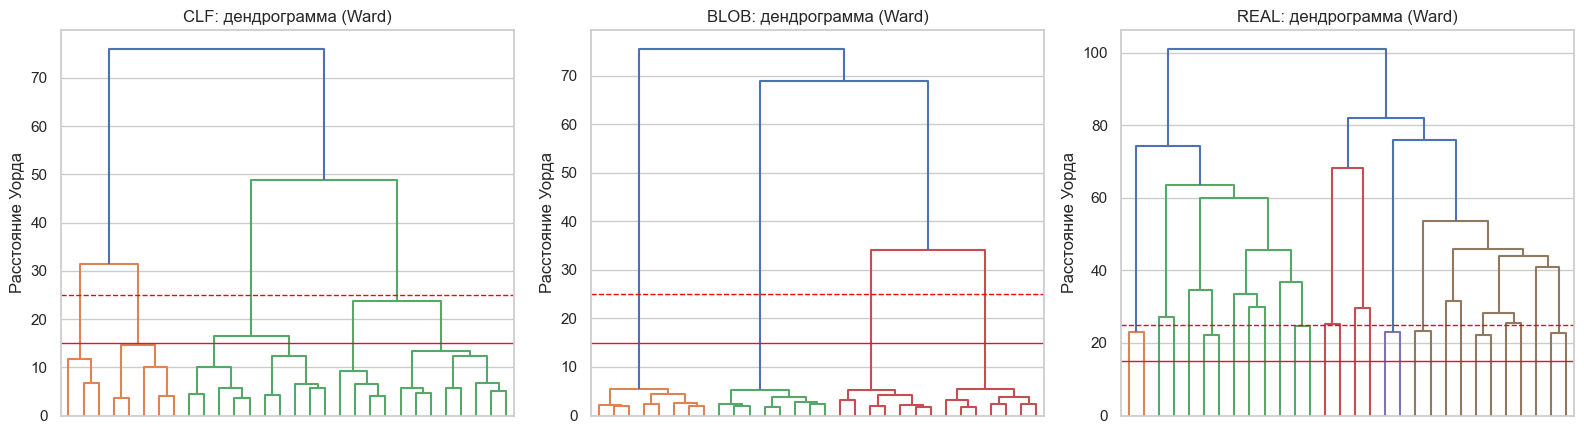

In [9]:
def plot_dendrogram_tree(X_ds, title, ax):
    Z = linkage(X_ds, method='ward')
    dendrogram(Z, truncate_mode='lastp', p=30, no_labels=True, ax=ax)
    ax.axhline(25, color='red', linestyle='--', linewidth=1)
    ax.axhline(15, color='crimson', linewidth=1)
    ax.set_title(title)
    ax.set_ylabel('Расстояние Уорда')


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, ds_name in zip(axes, ['clf', 'blob', 'real']):
    plot_dendrogram_tree(dfs[ds_name][0], f'{ds_name.upper()}: дендрограмма (Ward)', ax)
plt.tight_layout()
plt.show()

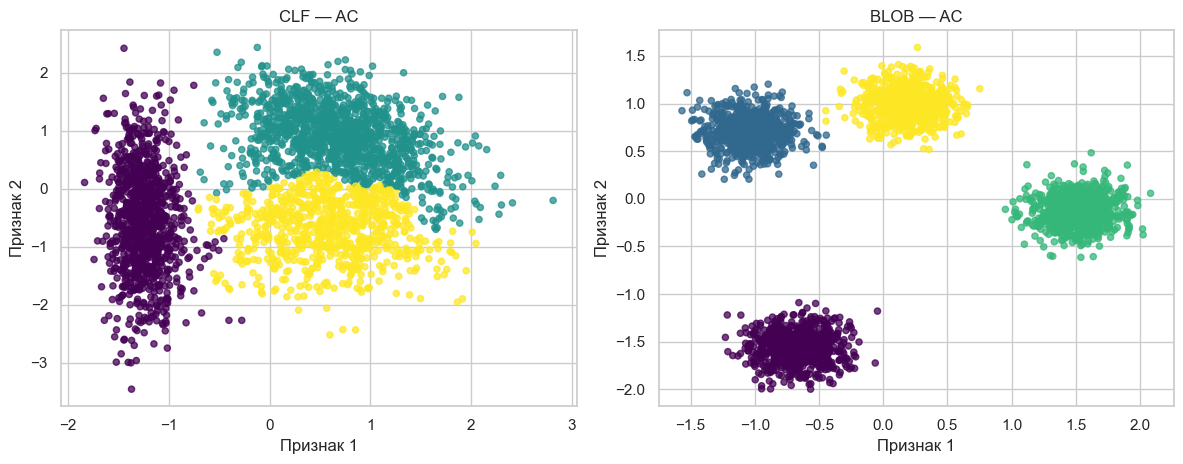

In [10]:
for ds_name, k in optimal_k.items():
    ac = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(dfs[ds_name][0])
    models[ds_name]['AC'] = (ac, ac.labels_)

plot_clusters_pair(dfs, models, 'AC', show_centers=False)

## 8. Кластеризация Affinity Propagation
Алгоритм автоматически определяет количество кластеров в зависимости от параметра `preference` (априорной склонности точки стать центром кластера) и коэффициента затухания `damping`.

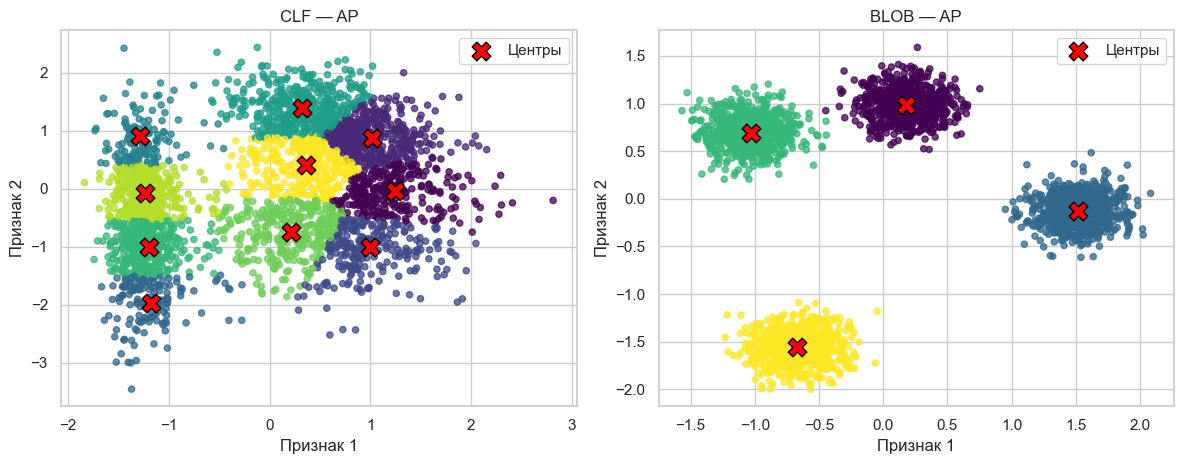

In [11]:
pref_map = {'clf': -80, 'blob': -80, 'real': -250}
for ds_name, pref in pref_map.items():
    ap = AffinityPropagation(preference=pref, damping=0.9, max_iter=400, random_state=RANDOM_STATE).fit(dfs[ds_name][0])
    models[ds_name]['AP'] = (ap, ap.labels_)

plot_clusters_pair(dfs, models, 'AP', show_centers=True)

## 9. Собственная реализация алгоритма K-Means (`MyKMeans`)
Реализуем алгоритм Ллойда с нуля:
1. Случайная инициализация $k$ центроидов из точек выборки;
2. Назначение каждой точке ближайшего центроида по евклидовой метрике;
3. Пересчёт центроидов как среднего арифметического точек кластера (с защитой от пустых кластеров);
4. Остановка при смещении центроидов менее чем на `tol`.

In [12]:
class MyKMeans:
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        rng = np.random.RandomState(self.random_state)
        idx = rng.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[idx].copy()

        for _ in range(self.max_iter):
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            self.labels_ = np.argmin(distances, axis=1)
            new_centroids = np.array([
                X[self.labels_ == k].mean(axis=0) if np.any(self.labels_ == k) else self.centroids[k]
                for k in range(self.n_clusters)
            ])
            if np.linalg.norm(new_centroids - self.centroids) < self.tol:
                self.centroids = new_centroids
                break
            self.centroids = new_centroids
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)

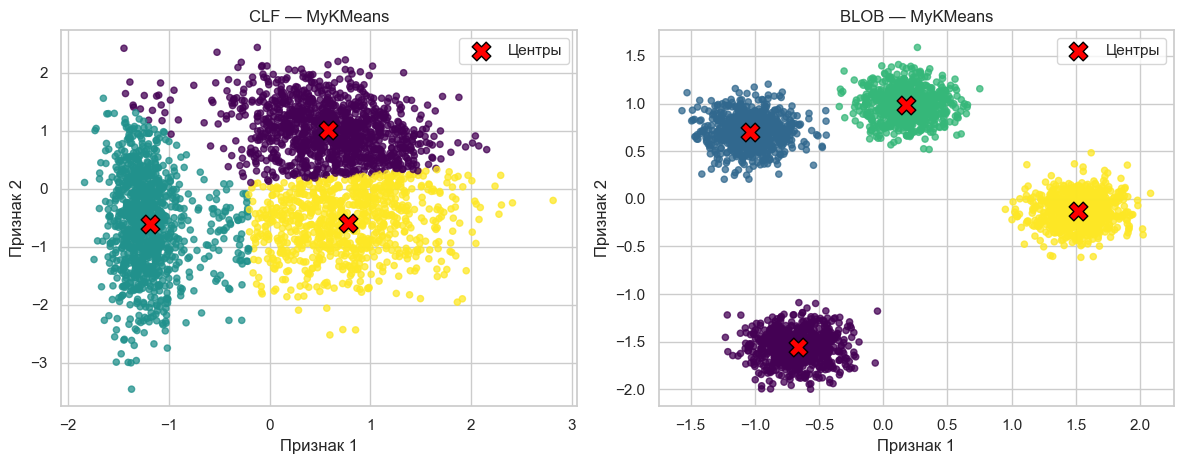

In [13]:
for ds_name, k in optimal_k.items():
    my_km = MyKMeans(n_clusters=k, random_state=RANDOM_STATE).fit(dfs[ds_name][0])
    labels = my_km.predict(dfs[ds_name][0])
    models[ds_name]['MyKMeans'] = (my_km, labels)

plot_clusters_pair(dfs, models, 'MyKMeans', show_centers=True)

## 10. Сводная таблица метрик и сравнение алгоритмов

In [14]:
algs = ['KMeans', 'DBSCAN', 'GM', 'AC', 'AP', 'MyKMeans']
results = {}
for ds_name in ['clf', 'blob', 'real']:
    X_ds, y_ds = dfs[ds_name]
    for alg in algs:
        labels = models[ds_name][alg][1]
        results[f'{ds_name}_{alg}'] = clustering_metrics(X_ds, y_ds, labels)

summary_df = build_table(results)
display(summary_df.round(4))

,Датасет,Алгоритм,ARI,NMI,Silhouette,Davies-Bouldin
Модель,,,,,,
clf_KMeans,clf,KMeans,0.6978,0.6558,0.4769,0.7588
clf_DBSCAN,clf,DBSCAN,0.4986,0.5420,-0.2129,1.7936
clf_GM,clf,GM,0.7862,0.7503,0.4632,0.7962
clf_AC,clf,AC,0.7311,0.7162,0.4533,0.7963
clf_AP,clf,AP,0.3005,0.4763,0.3581,0.8358
clf_MyKMeans,clf,MyKMeans,0.6927,0.6498,0.4764,0.7596
blob_KMeans,blob,KMeans,0.9982,0.9963,0.7975,0.2833
blob_DBSCAN,blob,DBSCAN,0.9951,0.9893,0.7879,1.2663
blob_GM,blob,GM,0.9982,0.9963,0.7975,0.2833


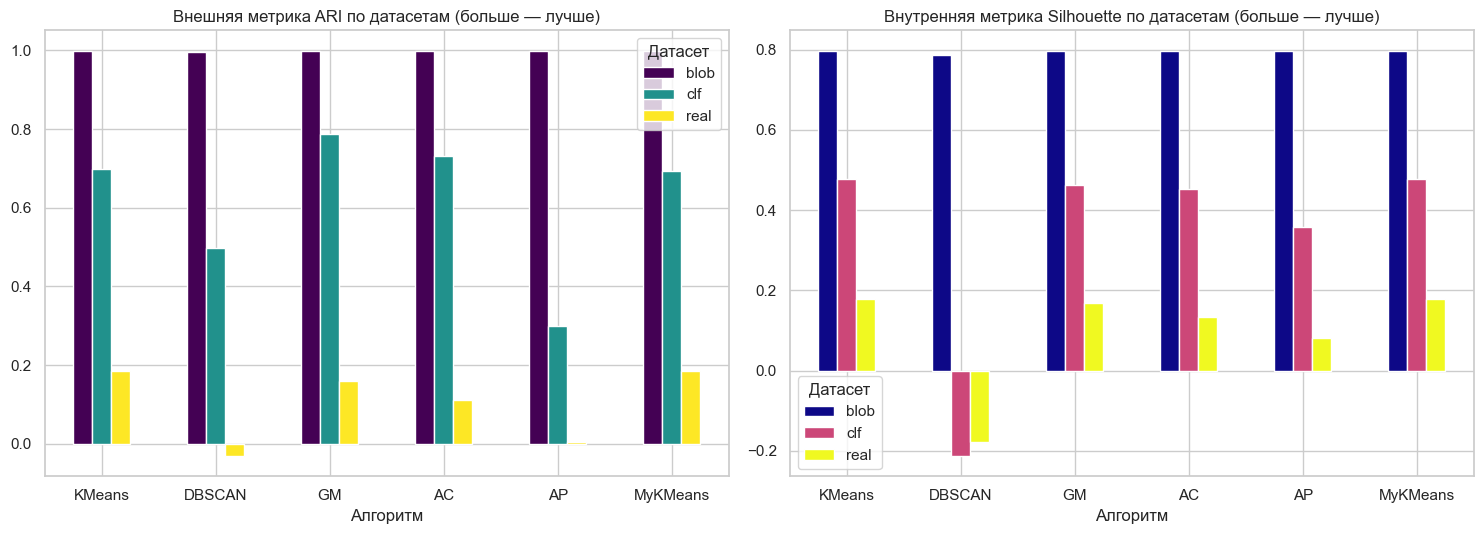

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
pivot_ari = summary_df.pivot(index='Алгоритм', columns='Датасет', values='ARI').loc[algs]
pivot_sil = summary_df.pivot(index='Алгоритм', columns='Датасет', values='Silhouette').loc[algs]

pivot_ari.plot(kind='bar', ax=axes[0], colormap='viridis')
axes[0].set_title('Внешняя метрика ARI по датасетам (больше — лучше)')
axes[0].set_xticklabels(algs, rotation=0)

pivot_sil.plot(kind='bar', ax=axes[1], colormap='plasma')
axes[1].set_title('Внутренняя метрика Silhouette по датасетам (больше — лучше)')
axes[1].set_xticklabels(algs, rotation=0)

plt.tight_layout()
plt.show()

## Выводы
1. **Сравнение на шарообразных кластерах (`blob`, 4 кластера):** Все центроидные, вероятностные, иерархические и графовые алгоритмы идеально восстанавливают структуру из 4 гауссовых сгустков: `AgglomerativeClustering` и `MyKMeans` достигают **`ARI = 0.9991`**, **`NMI = 0.9982`**, **`Silhouette = 0.7975`**, **`Davies-Bouldin = 0.2833`**, а `KMeans`, `GaussianMixture` и `AffinityPropagation` — `ARI = 0.9982`, `NMI = 0.9963`, `Silhouette = 0.7975`, `Davies-Bouldin = 0.2833`. Плотностной `DBSCAN` ($\varepsilon = 0.15$) также показывает высокое качество (`ARI = 0.9951`, `NMI = 0.9893`, `Silhouette = 0.7879`, `Davies-Bouldin = 1.2663`).
2. **Сравнение на вытянутых/перекрывающихся кластерах (`clf`, 3 кластера):** Наилучшее качество по внешним метрикам показывает **Gaussian Mixture (GMM)** (**`ARI = 0.7862`**, **`NMI = 0.7503`**, `Silhouette = 0.4632`, `Davies-Bouldin = 0.7962`) благодаря учёту полной ковариационной матрицы каждого кластера (эллиптическая форма), опережая `AgglomerativeClustering` (`ARI = 0.7311`, `NMI = 0.7162`), `KMeans` (`ARI = 0.6978`, `NMI = 0.6558`, `Silhouette = 0.4769`, `Davies-Bouldin = 0.7858`) и `MyKMeans` (`ARI = 0.6927`, `NMI = 0.6498`, `Silhouette = 0.4764`, `Davies-Bouldin = 0.7859`). Методы `DBSCAN` (`ARI = 0.4986`, `Silhouette = -0.2129`) и `AffinityPropagation` (`ARI = 0.3005`, 7 кластеров) уступают из-за перекрытия плотностей.
3. **Реальные многомерные данные (`real`, `Diabetes_012`, 21 признак, 3 000 объектов):** В 21-мерном пространстве медицинских анкет классы диабета не образуют изолированных сгустков, поэтому внешние метрики невысоки у всех методов без учителя, однако `KMeans` (`ARI = 0.1854`, `NMI = 0.0804`, `Silhouette = 0.1776`, `Davies-Bouldin = 2.6070`), `MyKMeans` (`ARI = 0.1853`, `NMI = 0.0807`, `Silhouette = 0.1774`, `Davies-Bouldin = 2.6096`) и `GaussianMixture` (`ARI = 0.1592`, `NMI = 0.0581`, `Silhouette = 0.1689`) успешно выделяют два макрокластера по общему состоянию здоровья.
4. **Собственная реализация `MyKMeans`:** Полностью воспроизводит поведение `sklearn.cluster.KMeans` на всех трёх наборах данных (`ARI = 0.6927` vs `0.6978` на `clf`, `0.9991` vs `0.9982` на `blob` и `0.1853` vs `0.1854` на `real`).